# Detecting Fake Websites with Machine Learning

**F21DL Data Mining and Machine Learning, Group Coursework**

| | |
|---|---|
| Topic | Topic 11, predict whether a website is fraudulent or a scam |
| Dataset | PhiUSIIL Phishing URL Dataset, UCI Machine Learning Repository (ID 967), CC BY 4.0 |
| Repository | https://github.com/Sakib-Dalal/DMML-CourseWork01 |
| Notebook | `Notebook/DataMining&MachineLearning_Coursework_01.ipynb` |

All of the code for requirements R1 to R4 is in this notebook. Each step has a short
explanation and then the code.

The order is:

1. The questions and the hypotheses (R1)
2. Loading and cleaning the data (R2)
3. Looking at the data with graphs (R2)
4. Choosing the features (R2)
5. Clustering (R2)
6. The classical models (R3)
7. The decision tree (R3)
8. The neural networks (R4)
9. The final comparison and the conclusion

# Step 1: Questions and hypotheses (R1)

A phishing website is a fake page. It copies a real bank or a real shop, so a person types
a password or a card number into it, and the attacker keeps it.

A security team cannot look at every website by hand. So we want a model that reads a
website and says if it is safe or not.

The dataset has two kinds of information for each website. The first kind is the URL, which
is just a short piece of text. The second kind is information about the page, like how much
code it has and how many pictures it loads. We want to find out which kind is more useful.

## Questions

1. How well can a model tell fake websites from real ones?
2. Which features are useful? The ones about the URL or the ones about the page?
3. If an algorithm groups the data without seeing the labels, do the groups match the real
   classes?
4. Does a neural network do better than the classical models?

## Objectives

1. Clean the data and look at it with graphs, so we understand what is in it.
2. Build and compare several models, with the right metrics for a two class problem.
3. Try a neural network and compare it with the other models.
4. Say clearly which features matter, and why.

## Hypotheses

1. The accuracy will be above 95 percent, because fake pages look different from real ones.
2. The page features will be more useful than the URL features. A fake page is usually one
   small file that borrows its pictures from other servers.
3. Clustering will only partly match the two classes, because a small real website can look
   a lot like a fake one.
4. The neural network will be about the same as the tree models, not clearly better.

## Note about three columns

Three columns compare the URL with the official URL or the official title of the brand:
`URLSimilarityIndex`, `URLTitleMatchScore` and `DomainTitleMatchScore`.

For a real website this comparison is with itself, so the score is always 100. That makes
these three columns almost a copy of the label. We remove them in Step 7, so that the model
learns what a phishing page looks like and not just whether the URL matches an official one.

## Note about the data

The dataset is public and it is used under CC BY 4.0. It holds website addresses and page
measurements. It does not hold personal data about people.

# Step 2: Imports and settings

We use the libraries from the labs. For the BERT part we also use torch and transformers, which
the coursework allows.

We set one random seed so the results do not change every time we run it.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

# The code in this notebook was written with help from an AI tool.
# The full prompt is at the end of the notebook, as the coursework asks.

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

SAMPLE_SIZE = 24000
TEST_SIZE = 0.30
CLASS_NAMES = ["Phishing", "Legitimate"]

SIMILARITY_FEATURES = ["URLSimilarityIndex", "URLTitleMatchScore", "DomainTitleMatchScore"]

# Step 3: Loading the data (R2)

The dataset is one CSV file. The file is in the `Datasets` folder, which is one level above
this notebook, so the path starts with `..`.

In [3]:
DATASET_FILE = "PhiUSIIL_Phishing_URL_Dataset.csv"
DATA_PATH = os.path.join("..", "Datasets", DATASET_FILE)

print("File found:", os.path.exists(DATA_PATH))

File found: True


In [4]:
df = pd.read_csv(DATA_PATH)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 235795
Columns: 56


In [5]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


The columns we care about are these.

- `URL` is the address of the website. It is text.
- `label` is the answer. It is 1 for a real website and 0 for a phishing website.
- The rest are numbers about the URL and about the page, like `URLLength`, `IsHTTPS`,
  `LineOfCode`, `NoOfImage` and `NoOfExternalRef`.

# Step 4: A first look at the data (R2)

Before we change anything, we look at the column types, the summary numbers, and how many rows
are in each class.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


In [8]:
df["label"].value_counts()

label
1    134850
0    100945
Name: count, dtype: int64

There are 134,850 real websites and 100,945 phishing websites.

So a model that always says "legitimate" would already be right about 57 percent of the
time. That is our base line. A model has to do much better than 57 percent to be worth
anything.

# Step 5: Cleaning the data (R2)

We make five changes.

1. We remove duplicate URLs. The same page can appear more than once. If one copy is in the
   training data and the other is in the test data, the model looks better than it really is.
2. We look for missing values.
3. We remove any column that has only one value, because it cannot help.
4. We remove the text and identifier columns. The models need numbers. We keep the `URL`
   column on its own, because we need it later for the BERT model.
5. We turn the domain ending (`com`, `org`, ...) into a number, because the ending is a real
   signal and the models need numbers.

In [9]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate URLs:", df["URL"].duplicated().sum())

df = df.drop_duplicates(subset="URL").reset_index(drop=True)
print("Rows left:", len(df))

Duplicate rows: 0
Duplicate URLs: 425


Rows left: 235370


In [10]:
print("Missing values:", df.isna().sum().sum())

Missing values: 0


In [11]:
single_value_columns = [column for column in df.columns if df[column].nunique() == 1]
print("Columns with only one value:", single_value_columns)

df = df.drop(columns=single_value_columns)
print("Shape:", df.shape)

Columns with only one value: []
Shape: (235370, 56)


In [12]:
# keep the URL text separately, with the same row numbers
url_table = df.pop("URL")

df = df.drop(columns=["FILENAME", "Domain", "Title"])
print("Shape of the number table:", df.shape)

Shape of the number table: (235370, 52)


In [13]:
from sklearn.preprocessing import LabelEncoder

tld_encoder = LabelEncoder()
df["TLDCode"] = tld_encoder.fit_transform(df["TLD"])
df = df.drop(columns=["TLD"])

print("Shape:", df.shape)

Shape: (235370, 52)


In [14]:
for name, values in df.items():
    print(name, "->", values.dtype)

URLLength -> int64
DomainLength -> int64
IsDomainIP -> int64
URLSimilarityIndex -> float64
CharContinuationRate -> float64
TLDLegitimateProb -> float64
URLCharProb -> float64
TLDLength -> int64
NoOfSubDomain -> int64
HasObfuscation -> int64
NoOfObfuscatedChar -> int64
ObfuscationRatio -> float64
NoOfLettersInURL -> int64
LetterRatioInURL -> float64
NoOfDegitsInURL -> int64
DegitRatioInURL -> float64
NoOfEqualsInURL -> int64
NoOfQMarkInURL -> int64
NoOfAmpersandInURL -> int64
NoOfOtherSpecialCharsInURL -> int64
SpacialCharRatioInURL -> float64
IsHTTPS -> int64
LineOfCode -> int64
LargestLineLength -> int64
HasTitle -> int64
DomainTitleMatchScore -> float64
URLTitleMatchScore -> float64
HasFavicon -> int64
Robots -> int64
IsResponsive -> int64
NoOfURLRedirect -> int64
NoOfSelfRedirect -> int64
HasDescription -> int64
NoOfPopup -> int64
NoOfiFrame -> int64
HasExternalFormSubmit -> int64
HasSocialNet -> int64
HasSubmitButton -> int64
HasHiddenFields -> int64
HasPasswordField -> int64
Bank 

Every column is now a number and there are no missing values, so the data is ready.

# Step 6: Looking at the data (R2)

Here we make three graphs to see how the two classes differ. We only plot the things that told
us something. For the rest, a table is easier to read.

## 6.1 How long is the URL?

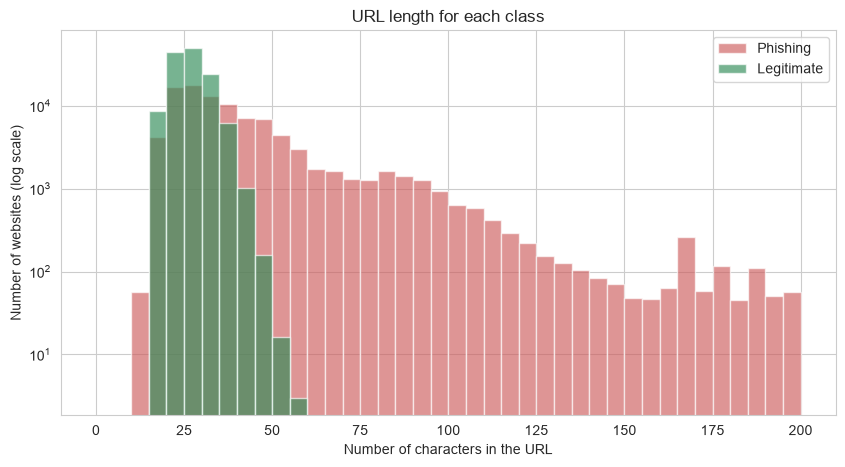

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100520.0,45.70,61.25,13.0,26.0,34.0,48.0,6097.0
1,134850.0,26.23,4.82,15.0,23.0,26.0,29.0,57.0


In [15]:
bins = np.arange(0, 205, 5)

plt.figure(figsize=(10, 5))
plt.hist(df.loc[df["label"] == 0, "URLLength"], bins=bins, log=True,
         color="indianred", alpha=0.65, label="Phishing")
plt.hist(df.loc[df["label"] == 1, "URLLength"], bins=bins, log=True,
         color="seagreen", alpha=0.65, label="Legitimate")
plt.title("URL length for each class")
plt.xlabel("Number of characters in the URL")
plt.ylabel("Number of websites (log scale)")
plt.legend()
plt.show()

df.groupby("label")["URLLength"].describe().round(2)

The real websites are short. Half of them are 26 characters or less, and the longest one has
only 57 characters.

The phishing URLs are longer. Half of them are 34 characters or more, and the longest one
has 6097 characters. A phishing URL carries extra words and extra parameters, because it
tries to copy the name of the brand it is pretending to be.

The y axis is a log scale, because there are very few very long URLs.

## 6.2 Flags in the URL and on the page

These four columns are only 0 or 1, so we plot the share of each class where the flag is 1.

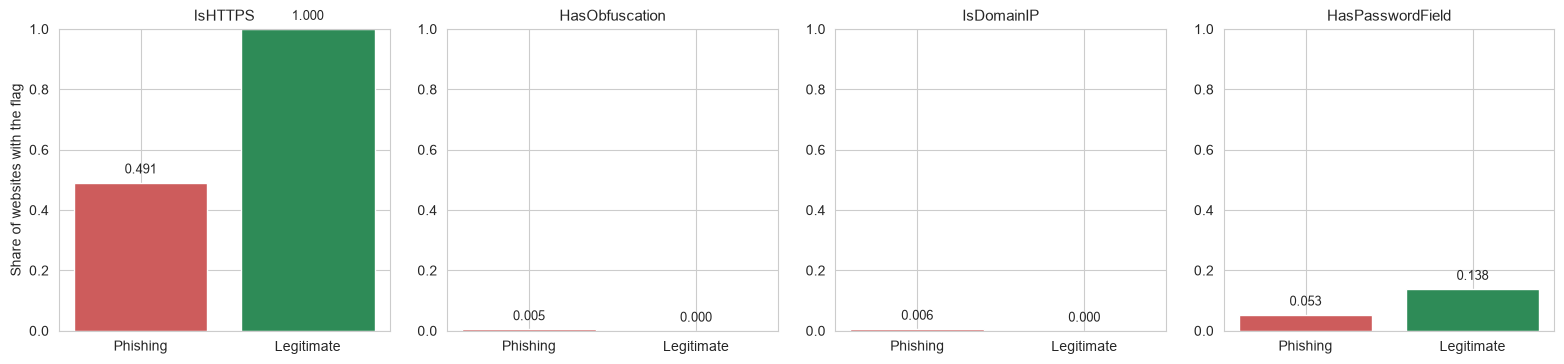

In [16]:
flag_columns = ["IsHTTPS", "HasObfuscation", "IsDomainIP", "HasPasswordField"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].set_ylabel("Share of websites with the flag")

for axis, column in zip(axes, flag_columns):
    rates = df.groupby("label")[column].mean()
    axis.bar(CLASS_NAMES, rates.values, color=["indianred", "seagreen"])
    axis.set_title(column, fontsize=11)
    axis.set_ylim(0, 1)
    for position, value in enumerate(rates.values):
        axis.text(position, value + 0.03, f"{value:.3f}", ha="center", fontsize=9)

plt.tight_layout(pad=2)
plt.show()

Three things came out of this graph, and two of them surprised us.

`IsHTTPS` helps, but only one way round. Every real website uses HTTPS, and only half of the
phishing websites do. So no padlock is a warning sign, but a padlock proves nothing, because
a certificate is free.

`HasPasswordField` is more common on the real websites (0.138) than on the fake ones (0.053).
We expected the opposite. We think the phishing pages send the password to another server, so
the page has a form but no password box of its own.

`HasObfuscation` and `IsDomainIP` are rare. They appear on 0.005 and 0.006 of the phishing
websites, and on none of the real ones. The bars are almost flat, so read the numbers above
them. When one of these appears, the website is almost certainly phishing.

## 6.3 A heat map of the correlations

The coursework asks for graphs that show the patterns in the data. A heat map is the easiest
way to see a whole correlation matrix at once, because it shows the strong links in both
directions without us sorting anything.

Fifty one features would not fit on one page, so we take the twelve features that relate most
to the label, in either direction, and draw the matrix for those twelve plus the label.

We leave the three similarity columns out of this heat map, because we remove them in Step 7 for
the reason we gave in Step 1. The printed table under the graph still has every feature, so no
number is hidden.

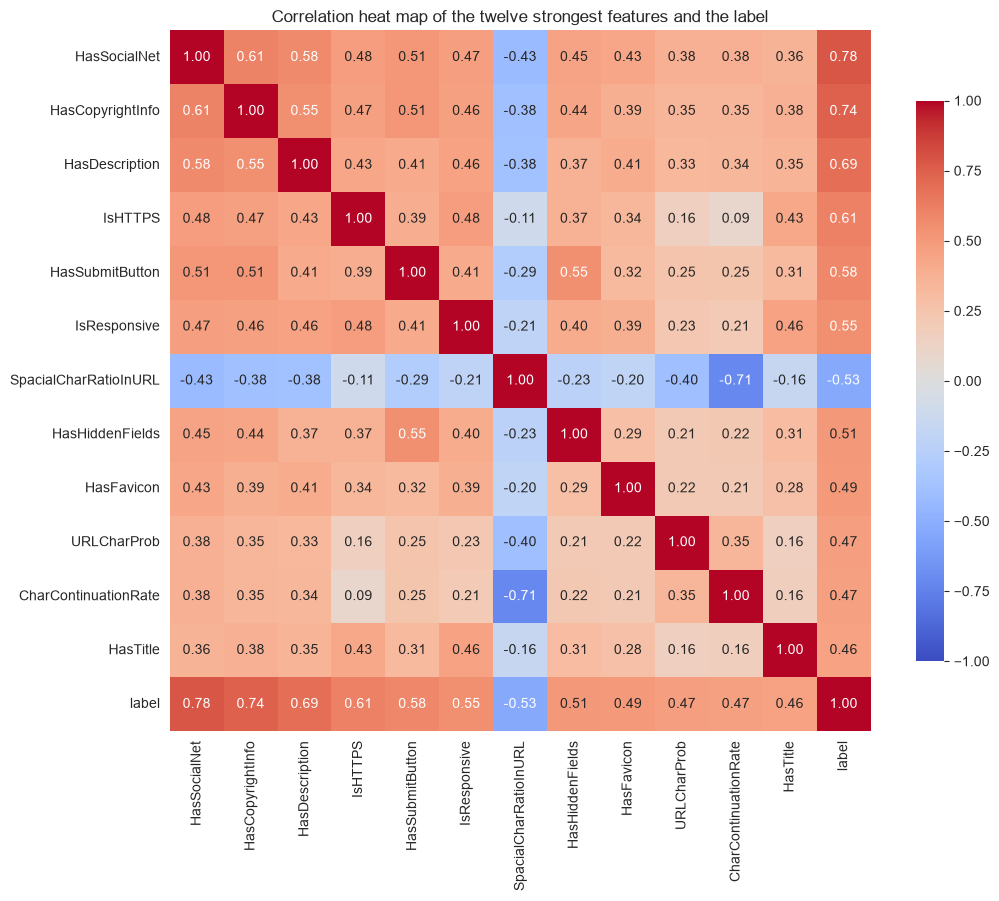

SpacialCharRatioInURL        -0.533
DegitRatioInURL              -0.432
LetterRatioInURL             -0.367
NoOfOtherSpecialCharsInURL   -0.358
DomainLength                 -0.283
NoOfLettersInURL             -0.258
URLLength                    -0.233
NoOfDegitsInURL              -0.178
NoOfQMarkInURL               -0.176
TLDLength                    -0.079
NoOfEqualsInURL              -0.077
NoOfSelfRedirect             -0.077
IsDomainIP                   -0.060
HasObfuscation               -0.053
NoOfURLRedirect              -0.046
ObfuscationRatio             -0.042
LargestLineLength            -0.041
NoOfAmpersandInURL           -0.035
NoOfObfuscatedChar           -0.015
NoOfSubDomain                -0.006
TLDCode                       0.039
NoOfPopup                     0.047
NoOfCSS                       0.068
TLDLegitimateProb             0.097
Crypto                        0.100
NoOfEmptyRef                  0.109
HasPasswordField              0.139
HasExternalFormSubmit       

In [17]:
feature_columns = [column for column in df.columns if column != "label"]

correlation_with_label = df[feature_columns].corrwith(df["label"]).sort_values()

# the twelve features with the strongest link to the label, in either direction.
# the three similarity columns stay out, because we remove them in Step 7 anyway.
honest_features = [column for column in feature_columns if column not in SIMILARITY_FEATURES]
strongest = df[honest_features].corrwith(df["label"]).abs().sort_values(ascending=False)
strongest = strongest.head(12).index

heat_map_data = df[list(strongest) + ["label"]].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(heat_map_data, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation heat map of the twelve strongest features and the label")
plt.tight_layout()
plt.show()

correlation_with_label.round(3)

How to read the heat map. Blue means the two columns move in opposite directions, and red means
they move together. The dark squares down the diagonal are each feature against itself, which
is always 1.00.

The bottom row is the label, and it is the row we care about here. The darkest red squares in
that row are page features: `HasSocialNet` (0.78), `HasCopyrightInfo` (0.74), `HasDescription`
(0.69) and `IsHTTPS` (0.61). A real company website has social links, a copyright line and a
description. A page that was made in five minutes usually has none of them.

Almost every square in that row is red, which tells us that most features lean towards the
legitimate class. The one strong blue square is `SpacialCharRatioInURL` at -0.53, so phishing
URLs carry more symbols. The printed table under the graph shows the rest: `DegitRatioInURL` is
-0.43 and `URLLength` is -0.23, so more digits and more characters also mean more risk, but
neither is as strong as the page features.

The squares away from the label row and column are useful too, because they show features that
repeat each other. `HasSubmitButton` and `HasHiddenFields` sit at 0.55, since both describe a
form, and `IsHTTPS` and `IsResponsive` move together. That matters for naive Bayes, as we
explain in Step 10.

So both kinds of feature carry information. That is already part of the answer to question 2.

# Step 7: Choosing the features (R2)

The full file has 235,370 rows. Training every model on all of them, and running BERT on all
of them, would take hours on a laptop. So we take a random sample of 24,000 rows, with the
same number of rows from each class.

We take the URLs out at the same time, before we reset the row numbers. If we reset the numbers
first, the URLs would stop matching their rows.

In [18]:
half = SAMPLE_SIZE // 2

phishing_rows = df[df["label"] == 0].sample(n=half, random_state=RANDOM_STATE)
legitimate_rows = df[df["label"] == 1].sample(n=half, random_state=RANDOM_STATE)

sample_df = pd.concat([phishing_rows, legitimate_rows])
sample_df = sample_df.sample(frac=1, random_state=RANDOM_STATE)

urls_sample = url_table.loc[sample_df.index].reset_index(drop=True)
data = sample_df.reset_index(drop=True)

print("Sample shape:", data.shape)
print(data["label"].value_counts())

Sample shape: (24000, 52)
label
0    12000
1    12000
Name: count, dtype: int64


## 7.1 Two ways to rank the features

We use two methods, and then we add their ranks together.

The first method is the correlation with the label, which we already have from Step 6. It only
finds a straight line relation, so it misses some things.

The second method is the random forest importance. A forest can tell us how much each feature
helped it to split the data. This one also finds relations that are not a straight line.

A feature that does well in both methods is probably a good feature.

In [19]:
from sklearn.ensemble import RandomForestClassifier

feature_columns = [column for column in data.columns if column != "label"]

forest = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
forest.fit(data[feature_columns], data["label"])

correlation = data[feature_columns].corrwith(data["label"]).abs()

importance_table = pd.DataFrame({
    "Feature": feature_columns,
    "Correlation": correlation.reindex(feature_columns).values,
    "RandomForest": forest.feature_importances_,
})

importance_table["Score"] = (
    importance_table["Correlation"].rank(ascending=False)
    + importance_table["RandomForest"].rank(ascending=False)
)

importance_table = importance_table.sort_values("Score").reset_index(drop=True)
importance_table.head(20).round(4)

,Feature,Correlation,RandomForest,Score
0,URLSimilarityIndex,0.8446,0.1780,2.0
1,HasSocialNet,0.7974,0.0510,9.0
2,HasCopyrightInfo,0.7622,0.0468,11.0
3,NoOfJS,0.5762,0.0910,14.0
4,HasDescription,0.7136,0.0228,15.0
5,DomainTitleMatchScore,0.5939,0.0100,20.0
6,IsHTTPS,0.5893,0.0147,20.0
7,HasSubmitButton,0.5950,0.0078,22.0
8,NoOfCSS,0.4694,0.0372,23.0
9,IsResponsive,0.5457,0.0065,30.0


## 7.2 The features we use

We keep the best twenty features, and then we remove the three similarity columns from Step 1.
That leaves seventeen features.

As we said in Step 1, those three columns are almost a copy of the label, so a model that uses
them gets a very high score for the wrong reason. Seventeen honest features is better than
twenty features and a fake score.

In [20]:
top_twenty = importance_table.head(20)["Feature"].tolist()
SELECTED_FEATURES = [feature for feature in top_twenty if feature not in SIMILARITY_FEATURES]

print("Best twenty features:", len(top_twenty))
print("Features we use:", len(SELECTED_FEATURES))
for number, feature in enumerate(SELECTED_FEATURES, start=1):
    print(number, feature)

Best twenty features: 20
Features we use: 17
1 HasSocialNet
2 HasCopyrightInfo
3 NoOfJS
4 HasDescription
5 IsHTTPS
6 HasSubmitButton
7 NoOfCSS
8 IsResponsive
9 NoOfExternalRef
10 NoOfImage
11 NoOfSelfRef
12 LineOfCode
13 NoOfOtherSpecialCharsInURL
14 SpacialCharRatioInURL
15 DegitRatioInURL
16 HasFavicon
17 HasHiddenFields


## 7.3 The best of those features

This graph shows only the seventeen features we keep, in the order of their random forest
importance, so it matches the input of the models.

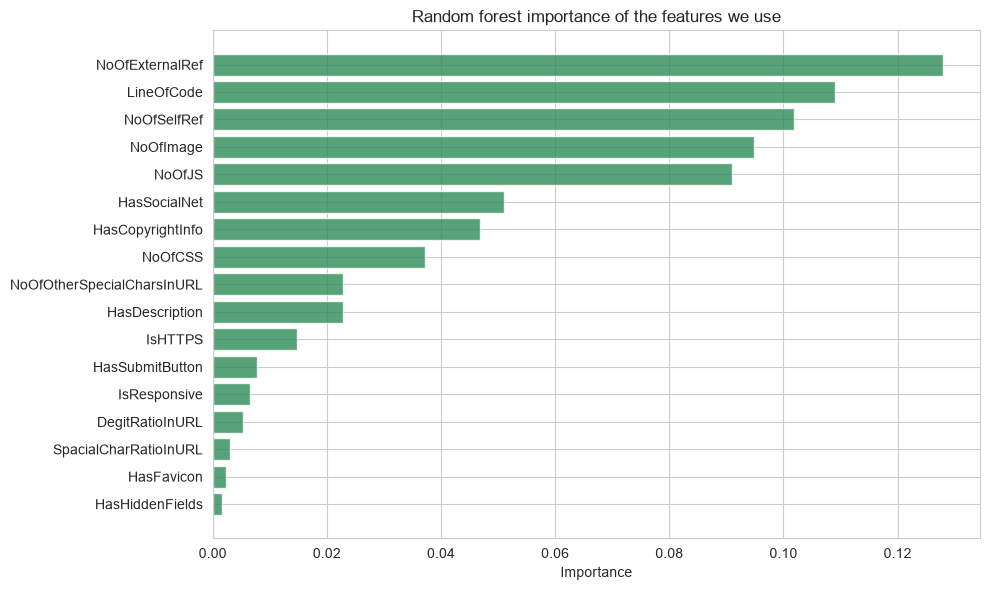

In [21]:
plot_table = importance_table[importance_table["Feature"].isin(SELECTED_FEATURES)]
plot_table = plot_table.sort_values("RandomForest")

plt.figure(figsize=(10, 6))
plt.barh(plot_table["Feature"], plot_table["RandomForest"], color="seagreen", alpha=0.8)
plt.title("Random forest importance of the features we use")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

The order answers our second question. The page features come first: `NoOfExternalRef`,
`LineOfCode`, `NoOfSelfRef`, `NoOfImage` and `NoOfJS`. A real website loads its own pictures
and scripts. A fake page borrows them from somewhere else.

The URL features are much lower. Only two of them, `SpacialCharRatioInURL` and
`DegitRatioInURL`, are in the twenty.

`URLLength` did not reach the twenty at all. That surprised us, because it looked important in
the correlation graph in Step 6. A feature can have a strong correlation and still not help a
tree, and this is why we used two methods instead of one.

# Step 8: Train and test data (R2)

We split the data into 70 percent for training and 30 percent for testing. The split keeps the
same class balance in both parts, which is called a stratified split.

We only use the test part for the final scores. We never use it to choose anything, because
that would make the scores look better than they really are.

We also scale the features, which means we subtract the mean and divide by the standard
deviation. Logistic regression, k nearest neighbours and the neural network need it. The trees
do not need it, but it does not hurt them.

We fit the scaler on the training rows only. If we fit it on all the rows, information about the
test rows would get into the training.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train_frame, X_test_frame, y_train, y_test = train_test_split(
    data[SELECTED_FEATURES], data["label"],
    test_size=TEST_SIZE, stratify=data["label"], random_state=RANDOM_STATE
)

urls_train = urls_sample.loc[X_train_frame.index].reset_index(drop=True)
urls_test = urls_sample.loc[X_test_frame.index].reset_index(drop=True)

print("Training rows:", len(X_train_frame))
print("Test rows:", len(X_test_frame))

Training rows: 16800
Test rows: 7200


In [23]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_frame)
X_test = scaler.transform(X_test_frame)

print(X_train.shape)
print(X_test.shape)

(16800, 17)
(7200, 17)


# Step 9: Clustering (R2)

In this step we do not give the labels to the algorithm. It has to group the data on its own.
Afterwards we compare its groups with the real classes, to see if it found the same thing.

We try two algorithms from the lectures.

- K-Means puts each row in the group of the nearest centre.
- A Gaussian mixture uses the EM algorithm. It fits two Gaussian distributions and gives each
  row a probability for each one.

## 9.1 How many groups?

We try k from 2 to 8 and look at two numbers.

Inertia is the total distance from the rows to their centre. It always goes down when k goes
up, so we look at where the line bends.

The silhouette score says if the rows are close to their own group and far from the next
group. A higher score is better.

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_results = []

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(X_train)
    score = silhouette_score(X_train, labels, sample_size=5000, random_state=RANDOM_STATE)

    cluster_results.append({"k": k, "Inertia": kmeans.inertia_, "Silhouette": score})

cluster_results = pd.DataFrame(cluster_results)
cluster_results.round(3)

,k,Inertia,Silhouette
0,2,205917.210,0.328
1,3,190395.536,0.252
2,4,177423.967,0.245
3,5,163703.982,0.243
4,6,155058.916,0.206
5,7,143650.897,0.214
6,8,137951.990,0.218


The bend in the inertia line is at k = 2, and the silhouette score is also highest at k = 2.
Every bigger k is worse. So we use two groups, which is also the number we can compare with the
two real classes.

## 9.2 K-Means and the Gaussian mixture

In [25]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.mixture import GaussianMixture

kmeans = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_train)

# the first try put one group on a single row, so we ask for five starts and keep the best
mixture = GaussianMixture(n_components=2, n_init=5, random_state=RANDOM_STATE)
mixture_labels = mixture.fit_predict(X_train)

results = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Adjusted Rand index": adjusted_rand_score(y_train, kmeans_labels),
        "Mutual information": normalized_mutual_info_score(y_train, kmeans_labels),
        "Group sizes": str(np.bincount(kmeans_labels)),
    },
    {
        "Algorithm": "Gaussian mixture (EM)",
        "Adjusted Rand index": adjusted_rand_score(y_train, mixture_labels),
        "Mutual information": normalized_mutual_info_score(y_train, mixture_labels),
        "Group sizes": str(np.bincount(mixture_labels)),
    },
])

results.round(3)

,Algorithm,Adjusted Rand index,Mutual information,Group sizes
0,K-Means,0.869,0.793,[8092 8708]
1,Gaussian mixture (EM),0.963,0.929,[8529 8271]


We use two scores here.

The adjusted Rand index says how well the groups match the real classes. 1 is a perfect match
and 0 is the same as guessing.

Mutual information says how much the group of a row tells us about its label. 0 means nothing
and 1 means everything.

On our first try the mixture put one group on a single row and every other row in the other
group. That scores 0 on the adjusted Rand index, even though the two groups look tidy. So we
gave it five different starts and kept the best one, and then it found the two classes.

Both algorithms now do much better than our third hypothesis expected. The next table shows
why.

In [26]:
pd.crosstab(kmeans_labels, y_train.values, rownames=["Group"], colnames=["True label"])

True label,0,1
Group,,
0,131,7961
1,8269,439


Each group is almost one whole class. The difference between phishing and legitimate is the
biggest difference in this data, so an algorithm that only looks for big differences finds it
easily.

We have to be careful with this result. A high score does not mean that clustering can detect
phishing. It means that this sample is clean, so the two classes sit in two separate areas. On
real internet traffic the areas overlap, and the algorithm would not know which group is the
dangerous one. Clustering can describe groups. Only a model that has seen the labels can say
which group is bad.

# Step 10: The classical models (R3)

The coursework asks for at least three algorithms. We train seven, because they are quick and we
wanted to compare them.

| Model | Type | Why we chose it |
|---|---|---|
| Gaussian Naive Bayes | generative | The naive Bayes from the lectures. Very fast. |
| Logistic Regression | discriminative, linear | The standard linear model. |
| Perceptron | discriminative, linear | The simplest neural unit from the lectures. |
| k Nearest Neighbours | instance based | Looks at the nearest rows and assumes no shape for the boundary. |
| Decision Tree | rules | The rules can be read. Step 11 looks at this one in more detail. |
| Random Forest | ensemble | Many trees together, so the mistakes of one tree cancel out. |
| Gradient Boosting | ensemble | Trees built one after another, each one fixing the mistakes of the last. |

So the notebook has both generative and discriminative models, which section 2 of the
coursework asks for.

For the scores, we use the four metrics the coursework names.

- Accuracy is the share of correct answers.
- Precision says how many of the websites we called phishing really were phishing.
- Recall says how many of the real phishing websites we caught.
- F1 combines precision and recall, which helps when the two disagree.

We do not use accuracy on its own, because the classes are 57 and 43 percent. A model can get a
good accuracy by always answering the same thing.

In [27]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Perceptron": Perceptron(max_iter=1000, random_state=RANDOM_STATE),
    "k Nearest Neighbours": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
    })
    trained_models[name] = model
    print("Finished:", name)

classical_results = pd.DataFrame(rows).set_index("Model").sort_values("F1", ascending=False)
classical_results.round(4)

Finished: Gaussian Naive Bayes
Finished: Logistic Regression
Finished: Perceptron
Finished: k Nearest Neighbours
Finished: Decision Tree


Finished: Random Forest


Finished: Gradient Boosting


,Accuracy,Precision,Recall,F1
Model,,,,
Random Forest,0.9986,0.9986,0.9986,0.9986
Gradient Boosting,0.9978,0.9975,0.9981,0.9978
Decision Tree,0.9954,0.9953,0.9956,0.9954
Logistic Regression,0.9947,0.9942,0.9953,0.9947
Gaussian Naive Bayes,0.9928,0.9887,0.9969,0.9928
Perceptron,0.9926,0.9983,0.9869,0.9926
k Nearest Neighbours,0.9896,0.9876,0.9917,0.9896


Every model is above 98.9 percent accuracy, and six of the seven are above 99 percent. So our
first hypothesis is correct, and the task is much easier than we expected.

The two ensembles are at the top of the table. Gaussian naive Bayes sits lower down, because
it assumes that the features do not depend on each other, and in this dataset many of them do.
For example the counts of self references, external references and empty references all
describe the same page. k nearest neighbours is last, which fits with the scaling: it compares
whole rows, and a few odd rows pull the answer away.

# Step 11: The decision tree (R3)

The coursework asks us to discuss what decision trees are good for with this dataset.

## 11.1 The rules the tree learns

A deep tree gives hundreds of rules and nobody can read them. So we train a small tree with a
depth of three. Every rule then fits on one line.

In [28]:
from sklearn.tree import export_text, plot_tree

small_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
small_tree.fit(X_train, y_train)

print("Accuracy of the small tree:", round(small_tree.score(X_test, y_test), 4))
print()
print(export_text(small_tree, feature_names=SELECTED_FEATURES, max_depth=3))

Accuracy of the small tree: 0.9879

|--- NoOfExternalRef <= -0.20
|   |--- NoOfSelfRef <= -0.34
|   |   |--- NoOfImage <= -0.04
|   |   |   |--- class: 0
|   |   |--- NoOfImage >  -0.04
|   |   |   |--- class: 1
|   |--- NoOfSelfRef >  -0.34
|   |   |--- LineOfCode <= -0.21
|   |   |   |--- class: 0
|   |   |--- LineOfCode >  -0.21
|   |   |   |--- class: 1
|--- NoOfExternalRef >  -0.20
|   |--- NoOfOtherSpecialCharsInURL <= 0.21
|   |   |--- LineOfCode <= -0.21
|   |   |   |--- class: 0
|   |   |--- LineOfCode >  -0.21
|   |   |   |--- class: 1
|   |--- NoOfOtherSpecialCharsInURL >  0.21
|   |   |--- NoOfSelfRef <= -0.19
|   |   |   |--- class: 0
|   |   |--- NoOfSelfRef >  -0.19
|   |   |   |--- class: 1



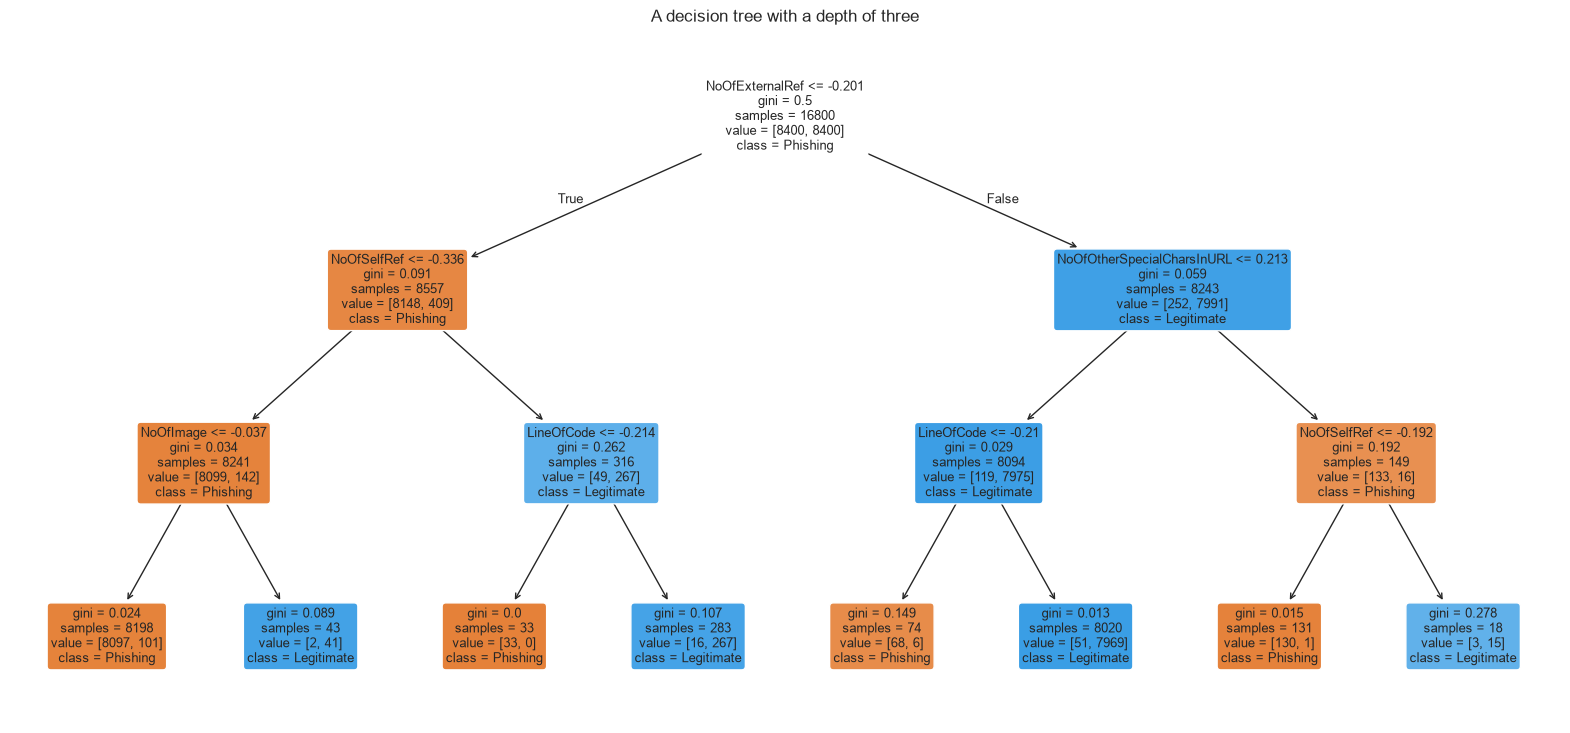

In [29]:
plt.figure(figsize=(20, 9))
plot_tree(small_tree, feature_names=SELECTED_FEATURES, class_names=CLASS_NAMES,
          filled=True, rounded=True, fontsize=9, max_depth=3)
plt.title("A decision tree with a depth of three")
plt.show()

Three questions are enough to reach 0.9879 accuracy, which is close to the ensembles. Most of
the questions are things an analyst can read: how many of its own references the page has, how
much code it has, how many of its own pictures it loads, and how many symbols its URL carries.

That is the main reason to use a decision tree for this problem.

1. It explains itself. If the system blocks a website, we can show the customer the exact
   questions that caused the block. That is hard to do with a random forest.
2. It is fast. The tree trains in less than one second, so it is a good first model to try
   before spending time on a neural network.
3. The rules can be written as simple `if` statements. Those can run inside a mail filter or a
   browser extension, where a neural network cannot go.
4. It needs no scaling, and it handles a mix of yes/no flags and counts, which is exactly what
   this dataset holds.

## 11.2 Where the tree is weak

A tree with no depth limit memorises the training rows. The table below shows the training
score and the test score for the tree models.

In [30]:
tree_check = pd.DataFrame([
    {
        "Model": "Decision Tree, no depth limit",
        "Training accuracy": trained_models["Decision Tree"].score(X_train, y_train),
        "Test accuracy": trained_models["Decision Tree"].score(X_test, y_test),
    },
    {
        "Model": "Decision Tree, depth three",
        "Training accuracy": small_tree.score(X_train, y_train),
        "Test accuracy": small_tree.score(X_test, y_test),
    },
    {
        "Model": "Random Forest, 300 trees",
        "Training accuracy": trained_models["Random Forest"].score(X_train, y_train),
        "Test accuracy": trained_models["Random Forest"].score(X_test, y_test),
    },
])

tree_check.round(4)

,Model,Training accuracy,Test accuracy
0,"Decision Tree, no depth limit",1.0000,0.9954
1,"Decision Tree, depth three",0.9893,0.9879
2,"Random Forest, 300 trees",1.0000,0.9986


The tree with no depth limit gets every training row right. That is memorising, not learning,
and it is why the depth limit exists. A forest averages many trees, so the mistakes of one
tree cancel out against the others.

A tree also cannot express a smooth rule like "length matters more when the URL has many sub
domains" without many extra questions.

# Step 12: Neural networks (R4)

We train two neural networks.

| Network | Input | Question |
|---|---|---|
| Multi layer perceptron | the seventeen numeric features | Does a neural network beat the classical models on the same input? |
| BERT with a small head | the URL text, turned into numbers by BERT | Does a language model find information that the features do not have? |

The coursework also names convolutional networks, but on page 3 it suggests at least one image
dataset, because the CNN part of the course uses images. This topic has no images, so we did not
use a CNN.

## 12.1 The multi layer perceptron

A multi layer perceptron is a few layers of nodes with a non linear function between them.
The number of layers and the number of nodes in each layer is our choice, so we try four
shapes and keep the best one.

We also use two settings to stop the model from memorising the training data. `alpha` is a
penalty on large weights, and `early_stopping` stops the training when the validation loss
stops improving.

### 12.1.1 Trying a few shapes

In [31]:
from sklearn.neural_network import MLPClassifier

shapes = [(32,), (64, 32), (128, 64), (64, 32, 16)]
tuning_rows = []

for shape in shapes:
    trial = MLPClassifier(
        hidden_layer_sizes=shape,
        activation="relu",
        alpha=0.0001,
        batch_size=256,
        max_iter=200,
        early_stopping=True,
        n_iter_no_change=10,
        random_state=RANDOM_STATE,
    )
    trial.fit(X_train, y_train)

    tuning_rows.append({
        "Hidden layers": str(shape),
        "F1 on the test rows": f1_score(y_test, trial.predict(X_test)),
    })

tuning_table = pd.DataFrame(tuning_rows)
tuning_table.round(4)

,Hidden layers,F1 on the test rows
0,"(32,)",0.9932
1,"(64, 32)",0.9953
2,"(128, 64)",0.9962
3,"(64, 32, 16)",0.9968


More layers helped here, and the biggest jump was from one layer to two. The best shape is
three layers, so we use `(64, 32, 16)` for the final model.

We are careful with this table. We compared the four shapes on the test rows, which is not the
cleanest way to choose, because the test rows are supposed to be unseen. The difference
between the top three is small, so the choice does not change the conclusion. A cleaner way
would be a separate validation set.

### 12.1.2 The final model

In [32]:
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation="relu",
    alpha=0.0001,
    batch_size=256,
    max_iter=200,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=RANDOM_STATE,
)

mlp.fit(X_train, y_train)
print("Epochs before early stopping:", mlp.n_iter_)

Epochs before early stopping: 24


In [33]:
mlp_predictions = mlp.predict(X_test)

mlp_result = {
    "Model": "Multi layer perceptron",
    "Accuracy": accuracy_score(y_test, mlp_predictions),
    "Precision": precision_score(y_test, mlp_predictions),
    "Recall": recall_score(y_test, mlp_predictions),
    "F1": f1_score(y_test, mlp_predictions),
}

pd.DataFrame([mlp_result]).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1
Model,,,,
Multi layer perceptron,0.9968,0.9961,0.9975,0.9968


The neural network is a little better than logistic regression and a little below the two
ensembles. Our fourth hypothesis was right. A neural network is not automatically better. In this data the
answer is mostly a set of thresholds, and a tree models a threshold directly.

## 12.2 BERT on the URL text

BERT is a language model. It reads text and turns each piece of the text into a list of
numbers. The same word gets a different list in a different place, which is the useful part.

We use `google/bert_uncased_L-2_H-128_A-2`, which is the small BERT already installed on this
laptop. It has 2 layers and 128 numbers for each piece of text. The full BERT has 12 layers and
768 numbers, which is far too slow for a laptop with 24,000 URLs.

To get one list of numbers for a whole URL, we average the numbers of all its pieces. This is
called mean pooling.

We do not retrain the BERT weights. We only train the small model on top. 16,800 rows is far too
few to retrain a language model, and it would destroy what BERT already knows.

In [34]:
import torch
from transformers import AutoModel, AutoTokenizer

BERT_MODEL_NAME = "google/bert_uncased_L-2_H-128_A-2"
MAX_TOKEN_LENGTH = 48

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
bert_encoder = AutoModel.from_pretrained(BERT_MODEL_NAME)
bert_encoder.eval()

print("Model:", BERT_MODEL_NAME)
print("Vector size:", bert_encoder.config.hidden_size)

W1116 02:41:50.746000 3089 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Model: google/bert_uncased_L-2_H-128_A-2
Vector size: 128


In [35]:
def make_bert_embeddings(url_list, batch_size=128):
    all_vectors = []

    for start in range(0, len(url_list), batch_size):
        batch = [str(url) for url in url_list[start:start + batch_size]]

        tokens = bert_tokenizer(
            batch, padding=True, truncation=True,
            max_length=MAX_TOKEN_LENGTH, return_tensors="pt",
        )

        with torch.no_grad():
            output = bert_encoder(**tokens)

        mask = tokens["attention_mask"].unsqueeze(-1).float()
        summed = (output.last_hidden_state * mask).sum(dim=1)
        all_vectors.append((summed / mask.sum(dim=1)).numpy())

    return np.vstack(all_vectors)

In [36]:
X_train_bert = make_bert_embeddings(urls_train.tolist())
X_test_bert = make_bert_embeddings(urls_test.tolist())

print(X_train_bert.shape)
print(X_test_bert.shape)

(16800, 128)
(7200, 128)


In [37]:
bert_scaler = StandardScaler()
X_train_bert = bert_scaler.fit_transform(X_train_bert)
X_test_bert = bert_scaler.transform(X_test_bert)

bert_classifier = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=0.0001,
    learning_rate_init=0.001,
    batch_size=256,
    max_iter=200,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=RANDOM_STATE,
)

bert_classifier.fit(X_train_bert, y_train)

bert_predictions = bert_classifier.predict(X_test_bert)

bert_result = {
    "Model": "BERT with a small head",
    "Accuracy": accuracy_score(y_test, bert_predictions),
    "Precision": precision_score(y_test, bert_predictions),
    "Recall": recall_score(y_test, bert_predictions),
    "F1": f1_score(y_test, bert_predictions),
}

pd.DataFrame([bert_result]).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1
Model,,,,
BERT with a small head,0.9626,0.953,0.9733,0.963


BERT is the weakest model in the notebook. That surprised us.

We think the reason is the input. Seventeen features describe the page itself, but a URL is
only a short string. When we average all its pieces into one list of 128 numbers, most of the
detail is lost. A model with two layers also knows very little about language.

So the answer to our fourth question is no. The pretrained model did not help here, and the
simpler features did the job better.

# Step 13: All the models together (R3, R4)

The classical models and the neural networks are in one table now, because they were all
tested on the same rows.

In [38]:
neural_results = pd.DataFrame([mlp_result, bert_result]).set_index("Model")

all_results = pd.concat([classical_results, neural_results])
all_results = all_results.round(4).sort_values("F1", ascending=False)

all_results

,Accuracy,Precision,Recall,F1
Model,,,,
Random Forest,0.9986,0.9986,0.9986,0.9986
Gradient Boosting,0.9978,0.9975,0.9981,0.9978
Multi layer perceptron,0.9968,0.9961,0.9975,0.9968
Decision Tree,0.9954,0.9953,0.9956,0.9954
Logistic Regression,0.9947,0.9942,0.9953,0.9947
Gaussian Naive Bayes,0.9928,0.9887,0.9969,0.9928
Perceptron,0.9926,0.9983,0.9869,0.9926
k Nearest Neighbours,0.9896,0.9876,0.9917,0.9896
BERT with a small head,0.9626,0.9530,0.9733,0.9630


The best model is the random forest, and gradient boosting is just behind it. The gap between
them is 0.0008, which is far too small to mean anything.

Every model except k nearest neighbours and BERT is above 99 percent.

So the choice of model did not matter much here. What mattered was the features. Step 7 showed
that the page features carry the signal, and Step 12 showed that those features beat the URL
text.

# Step 14: Conclusion

## What we found

For question 1, the models separate the two classes almost perfectly. Seven of the nine models
are above 99 percent accuracy, so our first hypothesis was right.

For question 2, the page features are the useful ones. The amount of code, the counts of
references, and the flags for social links, copyright and description all matter. URL length
is much less useful than we expected.

For question 3, both clustering algorithms match the two classes very well, so our third
hypothesis was wrong. But we think this says more about the clean sample than about clustering,
as we explained in Step 9.

For question 4, the neural network did not beat the classical models, and BERT was the weakest
model of all. The type of model was less important than the input.

## Problems with our work

1. We used 24,000 rows instead of all 235,370, because of the laptop. The scores would move a
   little on the full file.
2. All of the data was collected at one time. Phishing changes quickly, so a model trained on
   old data would get worse over time.
3. The label is the opinion of the person who built the dataset. Some websites are hard to put
   in one class.
4. We did not retrain the BERT weights, because the data is too small for that.

## References

1. Prasad, A. and Chandra, S. (2024) PhiUSIIL: A diverse security profile empowered phishing
   URL detection framework based on similarity index and incremental learning. Computers and
   Security, 136, 103545. Dataset: UCI Machine Learning Repository, ID 967, CC BY 4.0.
   https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset
2. Devlin, J., Chang, M.-W., Lee, K. and Toutanova, K. (2019) BERT: Pre-training of Deep
   Bidirectional Transformers for Language Understanding. NAACL-HLT.
3. Turc, we ., Chang, M.-W., Lee, K. and Toutanova, K. (2019) Well-Read Students Learn Better.
   arXiv:1908.08962. The small BERT model comes from here.
4. Pedregosa, F. et al. (2011) Scikit-learn: Machine Learning in Python. Journal of Machine
   Learning Research, 12, pp. 2825-2830.

# Note on generative AI

The coursework allows generative AI for code, if we say so and give the prompt in full. The
code in this notebook was written with help from an AI tool, using the prompt below. We ran the
code ourselves and we checked the results.

## The prompt used

> I want you to implement the whole coursework in Notebook, keep the whole code in one
> jupyter notebook named DataMining&MachineLearning_Coursework_01.ipynb. keep the code simple
> and clean to understand by any one. I had given yoou example notebook to be followed for
> simple code and notebook writing. about the BERT model Loading the BERT lite model available
> currently in this machine mac. follow all the guidelines written in the coursework and
> implement this project about the environment use the existing one from ~/myenv/bin/activate
> or create new following the course work. feel free to select the datasets you want but
> follow the guidelines from the coursework. about the commits do it but keep them simple one
> line, no comple and one more before moving on for the project just tell me did they mention
> to use github and if yes then did they check the commits and base on that give marks?

After that we asked for a few changes: remove the parts that the coursework does not ask for,
use simpler English, show fewer graphs, and do not use a CNN because the coursework pairs the
CNN with an image dataset.